**Week 4: Shopify Stock Visualization, Time-Series Analysis & Financial Insights**
**Dataset:** Shopify Stock Data (Preprocessed from Week 3)

**Main objective:** Visualize historical stock-price movements, calculate 20-day and 50-day Simple Moving Averages (SMA), analyze daily returns and volatility, and prepare a financial insights report.

Use the cleaned dataset exported from Week 3: Shopify_Stock_Cleaned.csv.

Step 1: Import required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

Step 2: Upload the Week 3 cleaned dataset

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/EDA-Skill/Shopify_Stock_Cleaned.csv")

df.head()

,date,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
0,2015-05-21 04:00:00+00:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,NaN,0.463,16.535717
1,2015-05-22 04:00:00+00:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,10.241433,0.510,19.562715
2,2015-05-26 04:00:00+00:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,4.733303,0.126,4.228185
3,2015-05-27 04:00:00+00:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-7.251262,0.381,12.422564
4,2015-05-28 04:00:00+00:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.181822,0.126,4.573500


Step 3: Understand the dataset

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (2469, 11)

Column Names:
Index(['date', 'open', 'high', 'low', 'close', 'adj_close', 'volume',
       'daily_price_change', 'daily_return_percentage', 'daily_range',
       'range_percentage'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2469 entries, 0 to 2468
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     2469 non-null   object 
 1   open                     2469 non-null   float64
 2   high                     2469 non-null   float64
 3   low                      2469 non-null   float64
 4   close                    2469 non-null   float64
 5   adj_close                2469 non-null   float64
 6   volume                   2469 non-null   int64  
 7   daily_price_change       2469 non-null   float64
 8   daily_return_percentage  2468 non-null   float64
 9   daily_range              2469 non-null  

,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
count,2469.000000,2469.000000,2469.000000,2469.000000,2469.000000,2.469000e+03,2469.000000,2468.000000,2469.000000,2469.000000
mean,48.464345,49.505495,47.347795,48.456613,48.456613,1.657049e+07,-0.007732,0.214806,2.157700,4.543249
std,43.633916,44.470235,42.642546,43.573362,43.573362,1.436909e+07,1.949302,3.712244,2.319697,2.543249
min,1.939000,1.985000,1.848000,1.933000,1.933000,1.039000e+06,-13.463997,-18.585338,0.037000,0.860652
25%,10.479000,10.635000,10.275000,10.450000,10.450000,8.098000e+06,-0.439995,-1.663313,0.351999,2.812456
50%,35.640999,36.879002,34.655998,35.874001,35.874001,1.275860e+07,0.005001,0.203627,1.470001,3.878589
75%,76.080002,77.169998,74.589996,75.800003,75.800003,2.060200e+07,0.466999,2.058009,3.197998,5.545096
max,171.800003,176.291794,168.509506,169.059998,169.059998,2.089590e+08,14.854996,23.838337,18.399002,27.099370


Step 4: Convert date and set the time-series index

In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce', utc=True)

df = df.dropna(subset=['date'])

df = df.sort_values('date')

df = df.set_index('date')

print("Starting Date:", df.index.min())
print("Ending Date:", df.index.max())

df.head()

Starting Date: 2015-05-21 04:00:00+00:00
Ending Date: 2025-03-14 04:00:00+00:00


,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage
date,,,,,,,,,,
2015-05-21 04:00:00+00:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,NaN,0.463,16.535717
2015-05-22 04:00:00+00:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,10.241433,0.510,19.562715
2015-05-26 04:00:00+00:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,4.733303,0.126,4.228185
2015-05-27 04:00:00+00:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-7.251262,0.381,12.422564
2015-05-28 04:00:00+00:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.181822,0.126,4.573500


Step 5: Check missing values and duplicates

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Dates:", df.index.duplicated().sum())

Missing Values:
open                       0
high                       0
low                        0
close                      0
adj_close                  0
volume                     0
daily_price_change         0
daily_return_percentage    1
daily_range                0
range_percentage           0
dtype: int64

Duplicate Dates: 0


Step 6: Calculate daily price change and daily returns

In [ ]:
df['daily_price_change'] = df['close'] - df['open']

df['daily_return'] = df['adj_close'].pct_change() * 100

df['daily_range'] = df['high'] - df['low']

df['volatility_percentage'] = (
    df['daily_range'] / df['open']
) * 100

display(df.head())

,open,high,low,close,adj_close,volume,daily_price_change,daily_return_percentage,daily_range,range_percentage,daily_return,volatility_percentage
date,,,,,,,,,,,,
2015-05-21 04:00:00+00:00,2.800,2.874,2.411,2.568,2.568,123039000,-0.232,NaN,0.463,16.535717,NaN,16.535717
2015-05-22 04:00:00+00:00,2.607,3.110,2.600,2.831,2.831,28412000,0.224,10.241433,0.510,19.562715,10.241433,19.562715
2015-05-26 04:00:00+00:00,2.980,3.034,2.908,2.965,2.965,8202000,-0.015,4.733303,0.126,4.228185,4.733303,4.228185
2015-05-27 04:00:00+00:00,3.067,3.081,2.700,2.750,2.750,7976000,-0.317,-7.251262,0.381,12.422564,-7.251262,12.422564
2015-05-28 04:00:00+00:00,2.755,2.774,2.648,2.745,2.745,4000000,-0.010,-0.181822,0.126,4.573500,-0.181822,4.573500


Step 7: Visualize historical closing prices

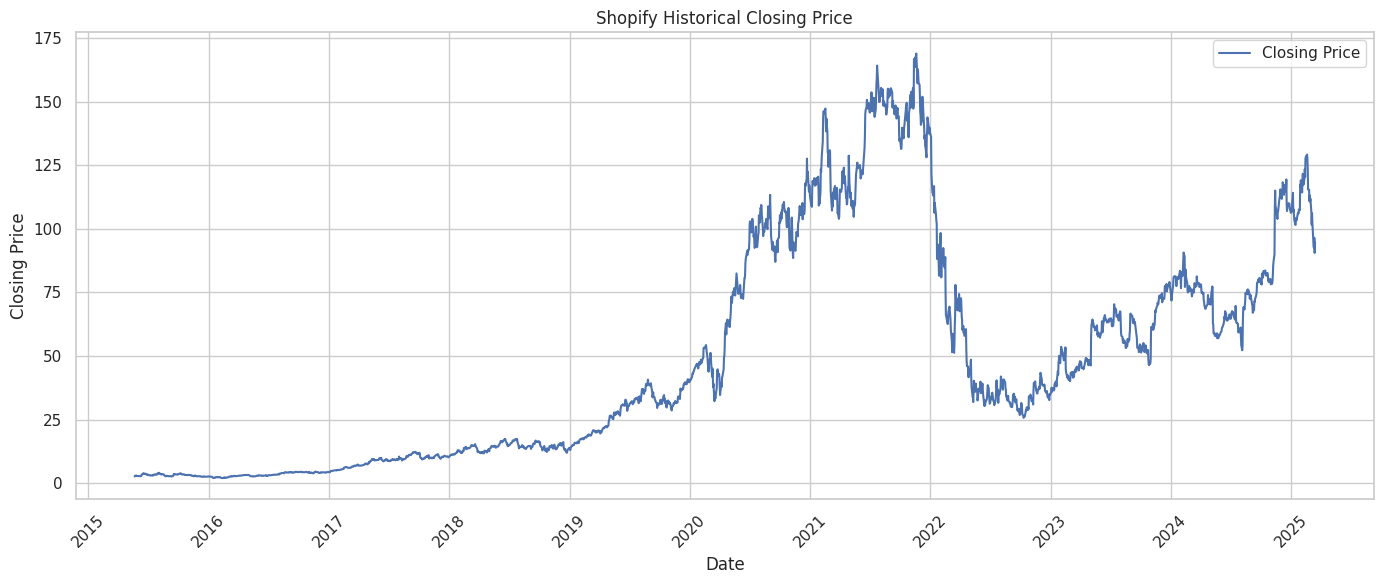

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['close'], label='Closing Price')

plt.title('Shopify Historical Closing Price')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 8: Visualize Open, High, Low and Close prices

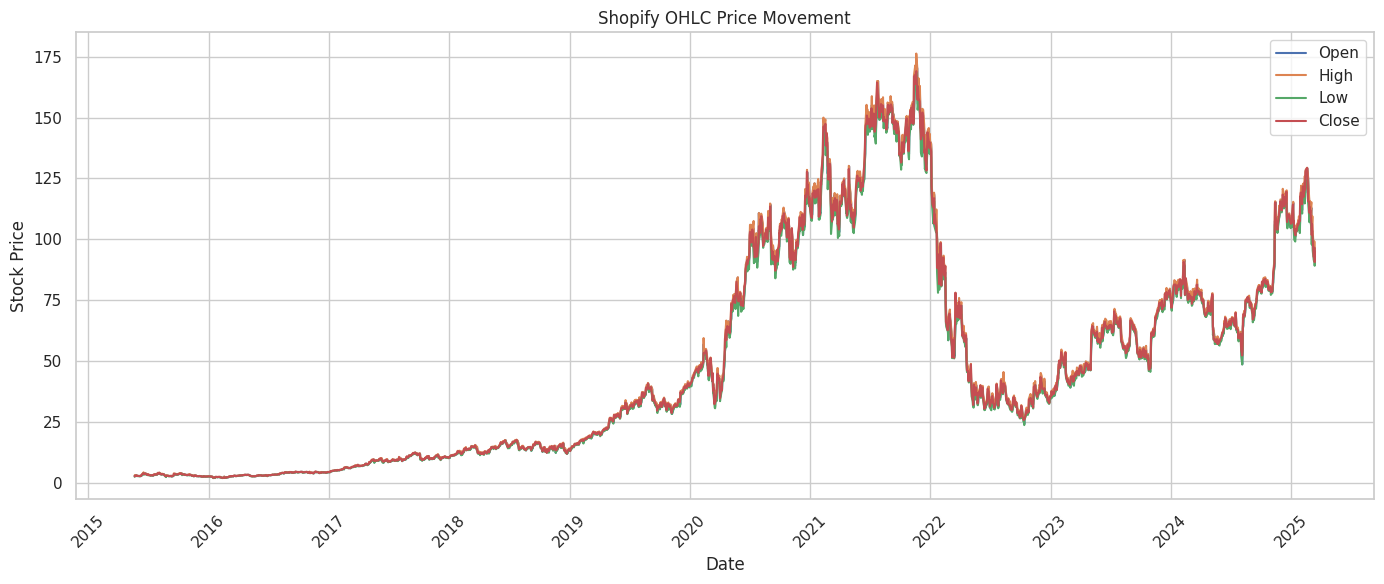

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['open'], label='Open')
plt.plot(df.index, df['high'], label='High')
plt.plot(df.index, df['low'], label='Low')
plt.plot(df.index, df['close'], label='Close')

plt.title('Shopify OHLC Price Movement')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 9: Visualize trading volume over time

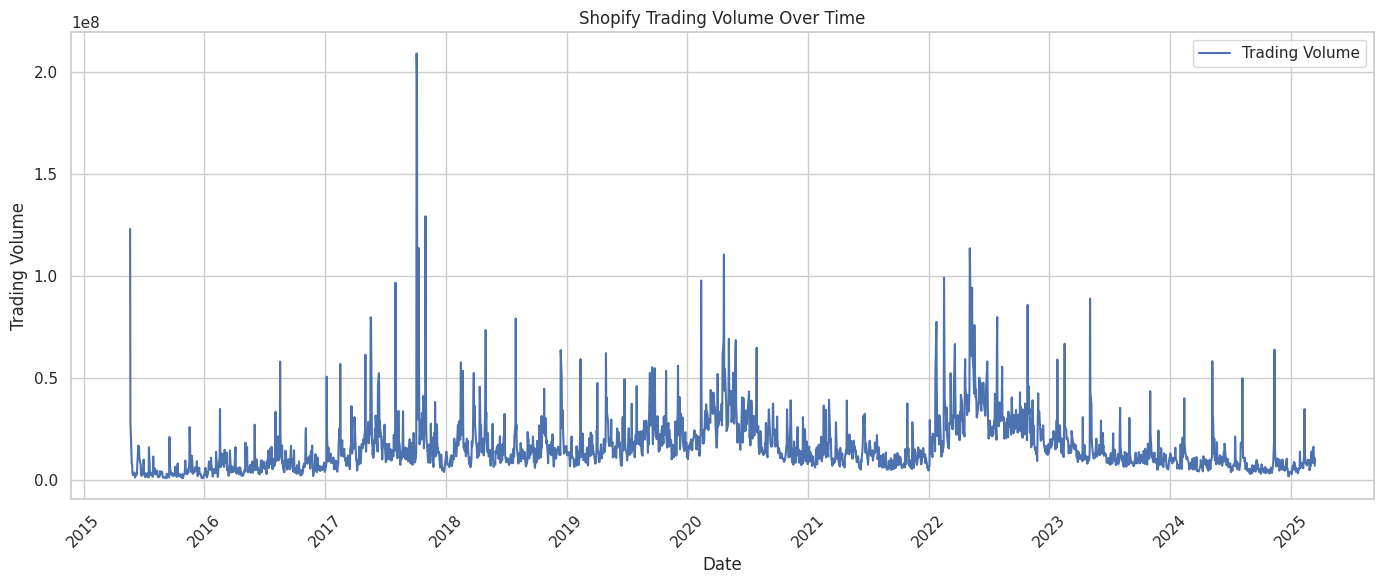

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['volume'], label='Trading Volume')

plt.title('Shopify Trading Volume Over Time')
plt.xlabel('Date')
plt.ylabel('Trading Volume')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 10: Calculate 20-day and 50-day Simple Moving Averages

In [ ]:
df['SMA_20'] = df['close'].rolling(window=20).mean()

df['SMA_50'] = df['close'].rolling(window=50).mean()

display(df[['close', 'SMA_20', 'SMA_50']].tail())

,close,SMA_20,SMA_50
date,,,
2025-03-10 04:00:00+00:00,92.750000,114.415001,111.7678
2025-03-11 04:00:00+00:00,92.949997,113.067500,111.4232
2025-03-12 04:00:00+00:00,96.529999,111.714500,111.1546
2025-03-13 04:00:00+00:00,90.589996,110.219500,110.8028
2025-03-14 04:00:00+00:00,94.849998,108.579500,110.5660


Step 11: Visualize closing price with moving averages

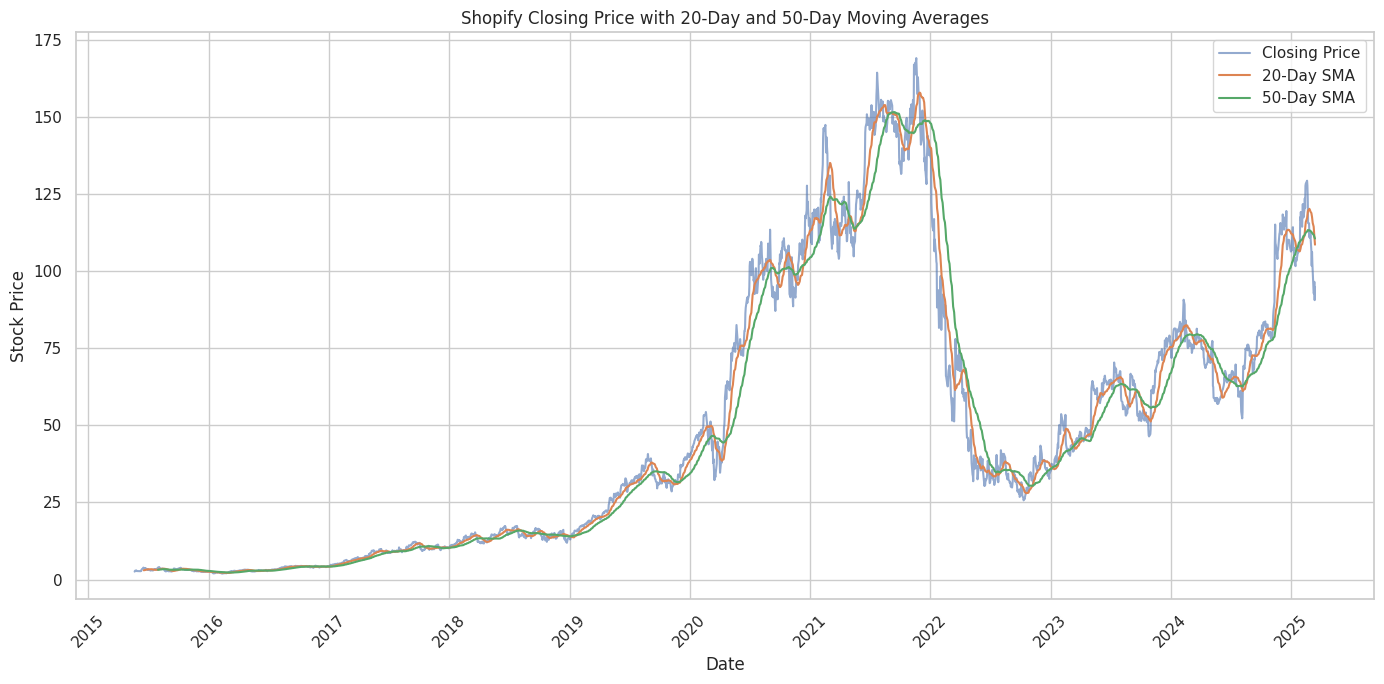

In [ ]:
plt.figure(figsize=(14, 7))

plt.plot(df.index, df['close'], label='Closing Price', alpha=0.6)
plt.plot(df.index, df['SMA_20'], label='20-Day SMA')
plt.plot(df.index, df['SMA_50'], label='50-Day SMA')

plt.title('Shopify Closing Price with 20-Day and 50-Day Moving Averages')
plt.xlabel('Date')
plt.ylabel('Stock Price')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 12: Analyze daily return distribution

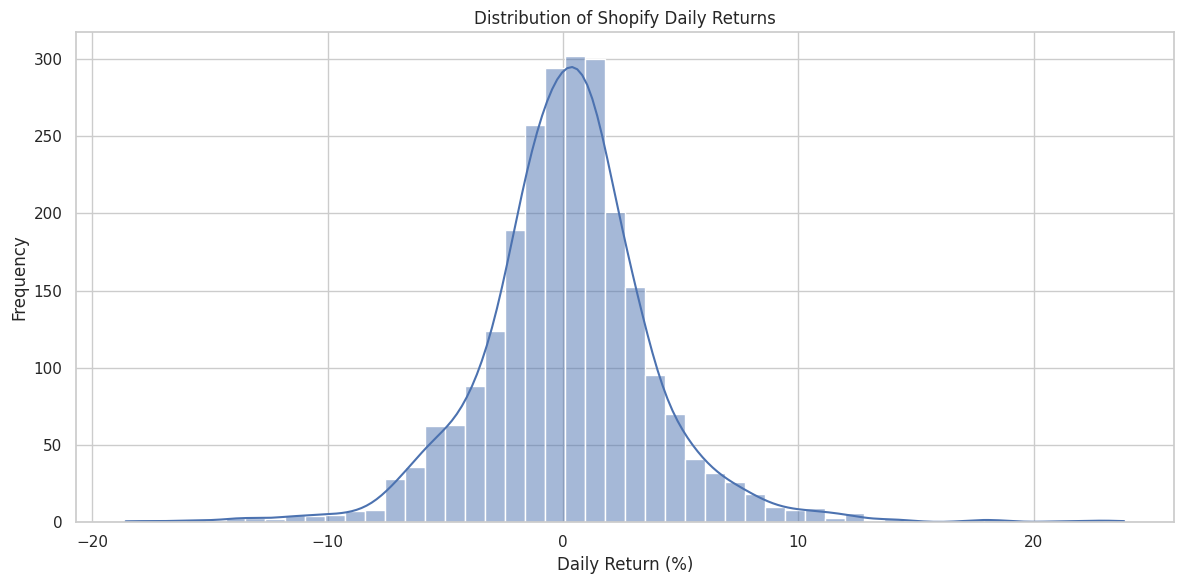

In [ ]:
plt.figure(figsize=(12, 6))

sns.histplot(
    df['daily_return'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Shopify Daily Returns')
plt.xlabel('Daily Return (%)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Step 13: Analyze daily returns using a box plot

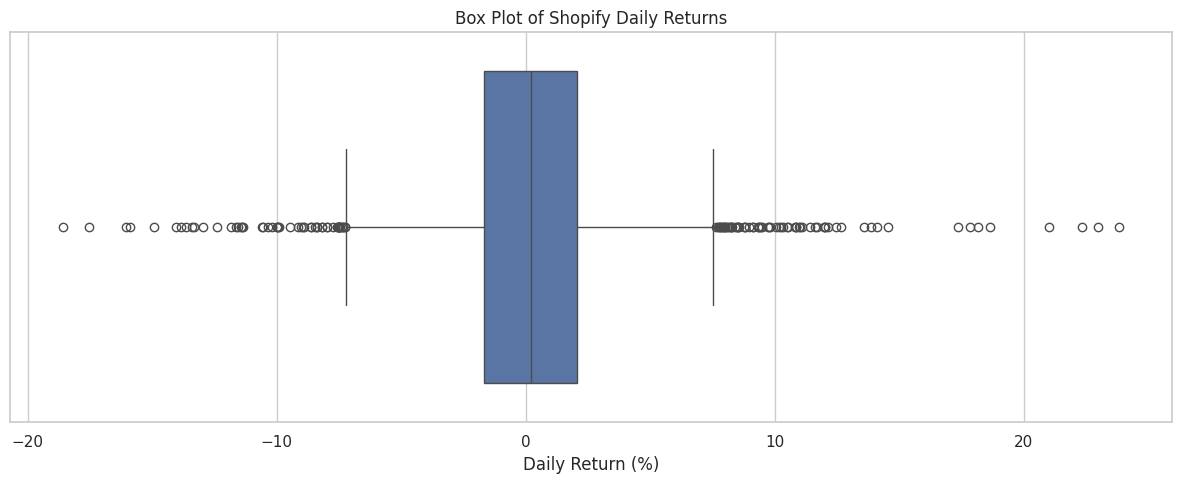

In [ ]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df['daily_return'].dropna())

plt.title('Box Plot of Shopify Daily Returns')
plt.xlabel('Daily Return (%)')

plt.tight_layout()
plt.show()

Step 14: Analyze daily price change

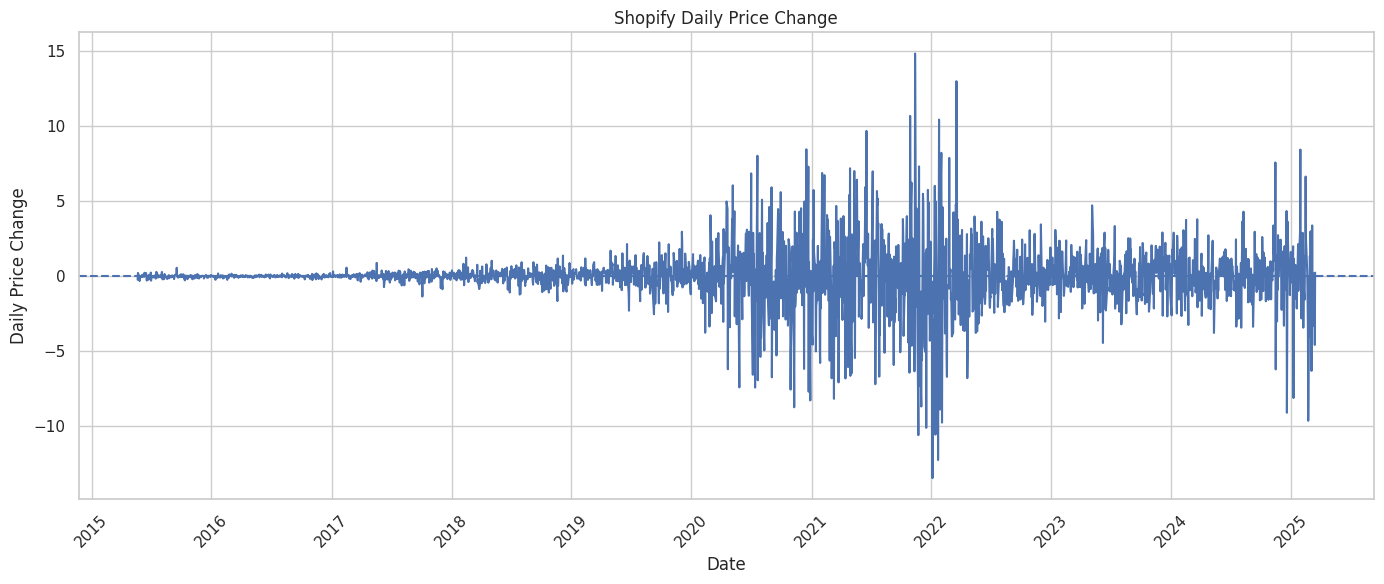

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['daily_price_change'])

plt.axhline(y=0, linestyle='--')

plt.title('Shopify Daily Price Change')
plt.xlabel('Date')
plt.ylabel('Daily Price Change')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 14: Analyze daily price change

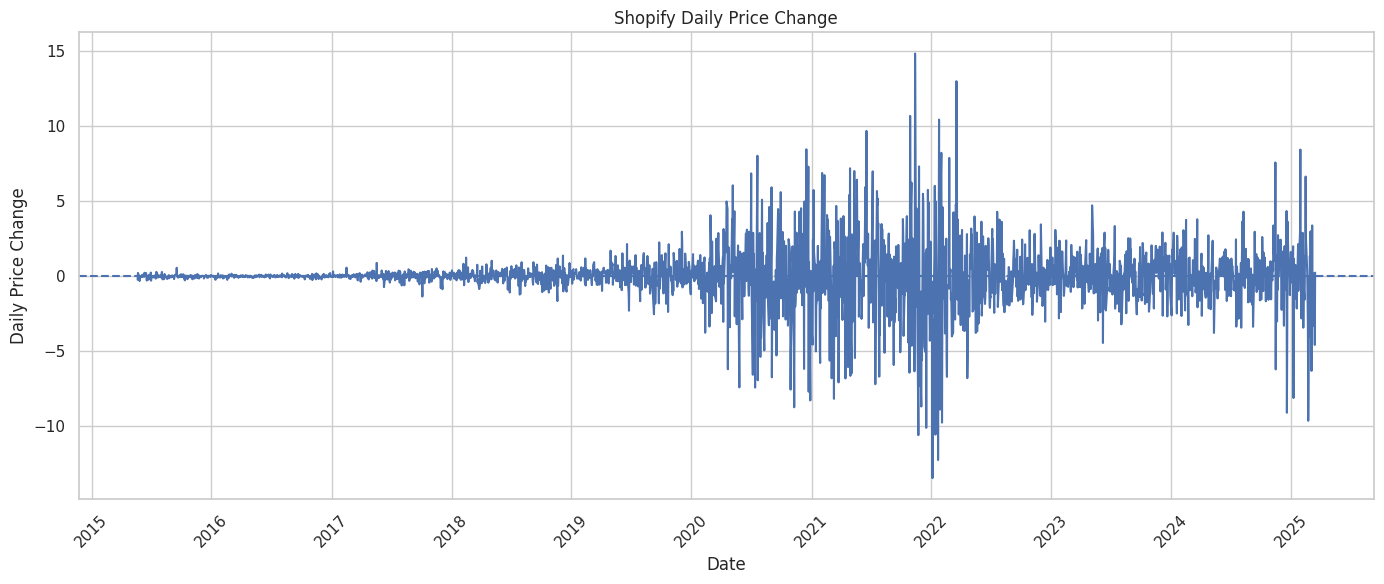

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(df.index, df['daily_price_change'])

plt.axhline(y=0, linestyle='--')

plt.title('Shopify Daily Price Change')
plt.xlabel('Date')
plt.ylabel('Daily Price Change')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 15: Analyze volatility over time

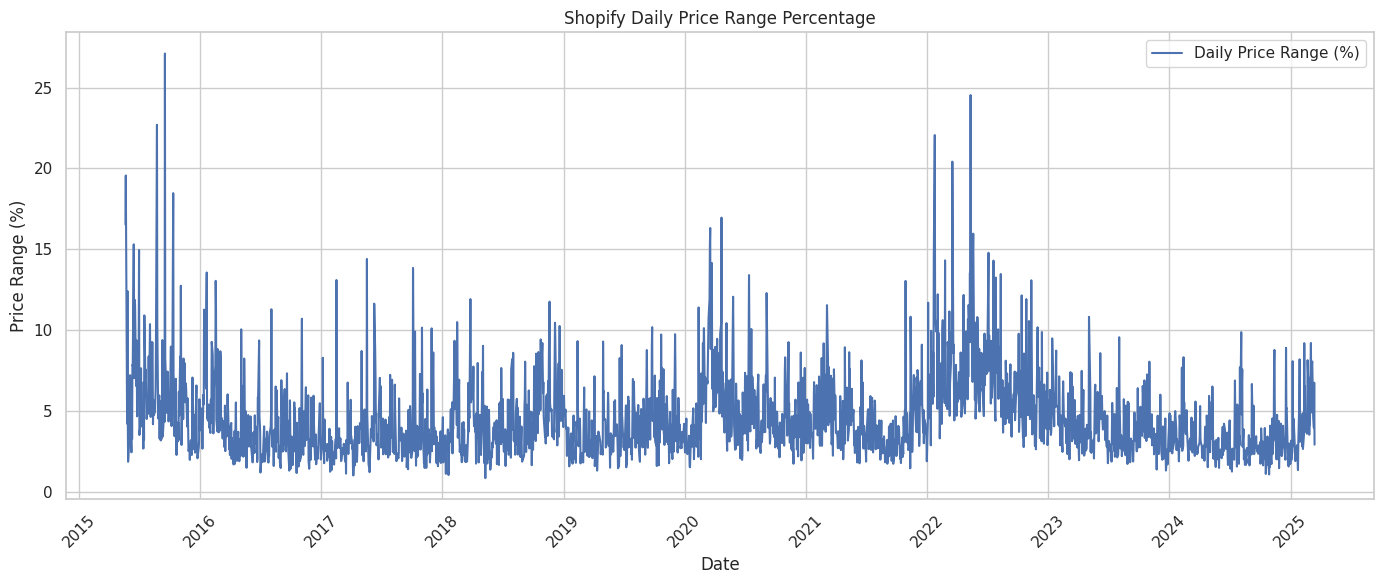

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df['volatility_percentage'],
    label='Daily Price Range (%)'
)

plt.title('Shopify Daily Price Range Percentage')
plt.xlabel('Date')
plt.ylabel('Price Range (%)')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 16: Calculate rolling volatility

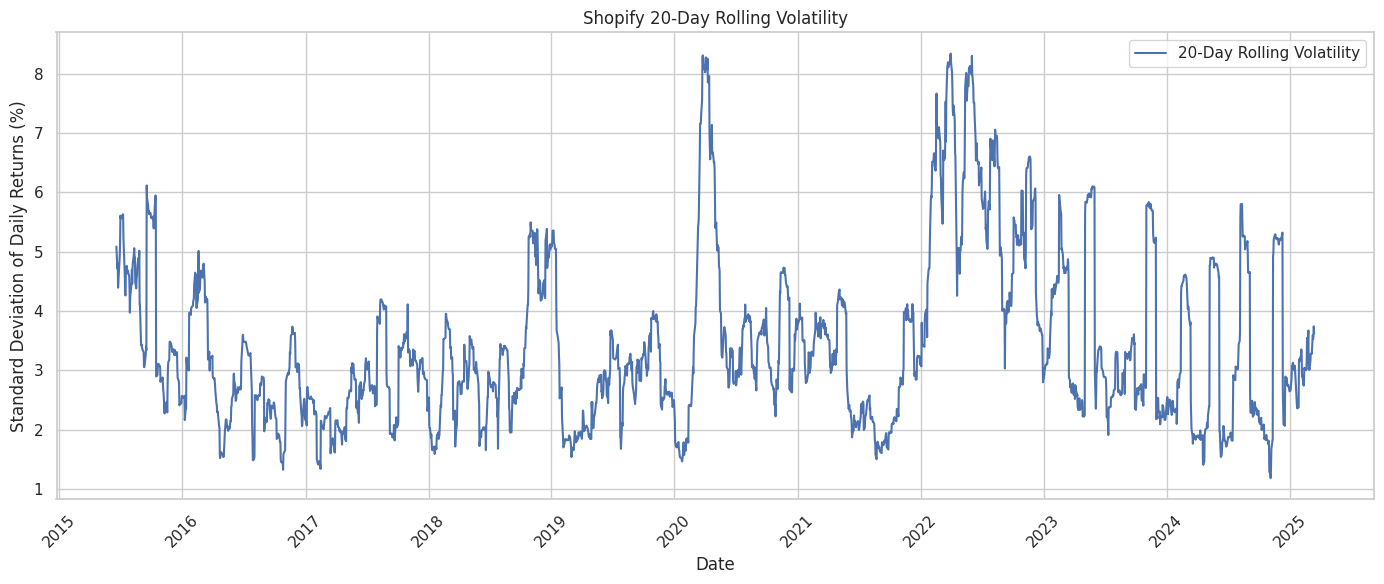

In [ ]:
df['rolling_volatility_20'] = (
    df['daily_return'].rolling(window=20).std()
)

plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df['rolling_volatility_20'],
    label='20-Day Rolling Volatility'
)

plt.title('Shopify 20-Day Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Standard Deviation of Daily Returns (%)')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Step 17: Analyze the relationship between volume and daily returns

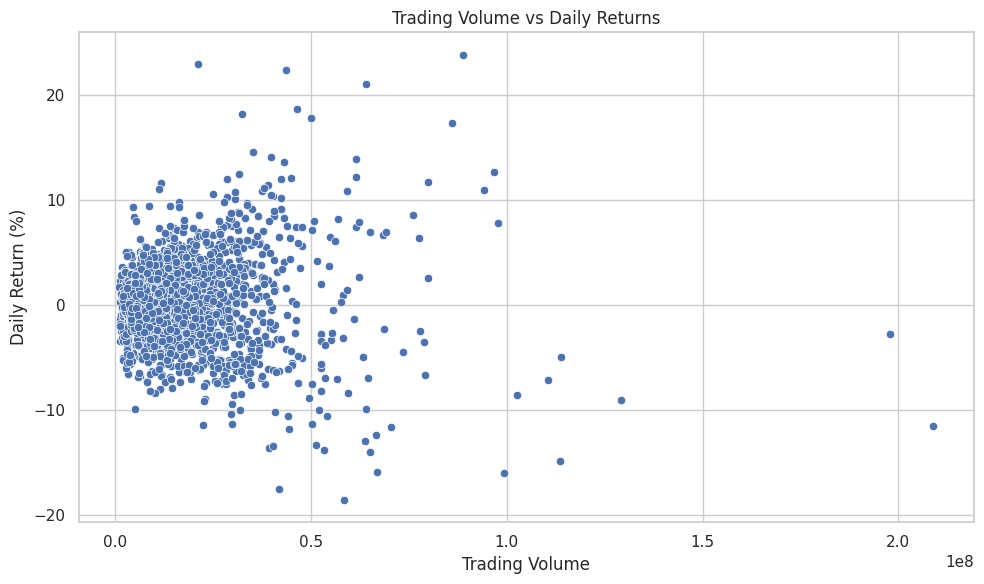

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='volume',
    y='daily_return'
)

plt.title('Trading Volume vs Daily Returns')
plt.xlabel('Trading Volume')
plt.ylabel('Daily Return (%)')

plt.tight_layout()
plt.show()

Step 18: Analyze correlations

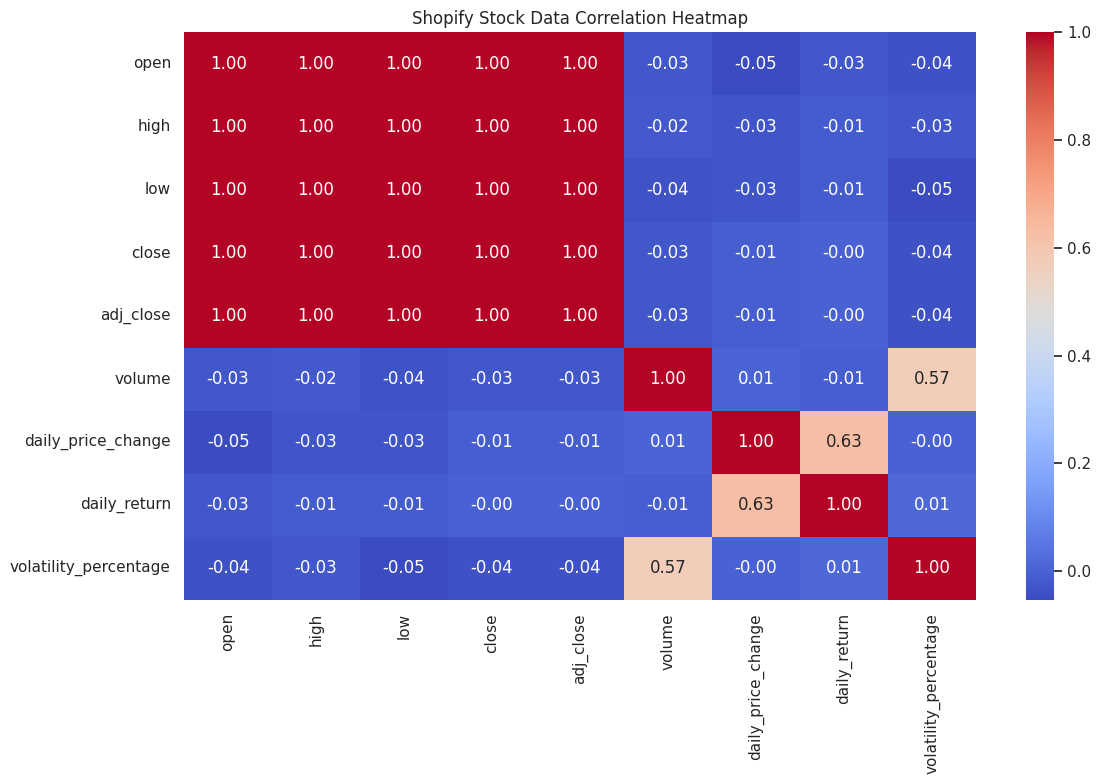

In [ ]:
correlation_columns = [
    'open',
    'high',
    'low',
    'close',
    'adj_close',
    'volume',
    'daily_price_change',
    'daily_return',
    'volatility_percentage'
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Shopify Stock Data Correlation Heatmap')

plt.tight_layout()
plt.show()

Step 19: Create monthly stock-price summary

In [ ]:
monthly_summary = df.resample('ME').agg({
    'open': 'first',
    'high': 'max',
    'low': 'min',
    'close': 'last',
    'volume': 'sum',
    'daily_return': 'mean'
})

monthly_summary.head()

,open,high,low,close,volume,daily_return
date,,,,,,
2015-05-31 00:00:00+00:00,2.800,3.110,2.411,2.720,174183000,1.326182
2015-06-30 00:00:00+00:00,2.720,4.213,2.551,3.395,131118000,1.128543
2015-07-31 00:00:00+00:00,3.403,4.025,2.850,3.739,89926000,0.535978
2015-08-31 00:00:00+00:00,3.749,4.111,2.270,2.754,65836000,-1.369592
2015-09-30 00:00:00+00:00,2.729,3.795,2.555,3.520,72092000,1.306413


Step 20: Visualize monthly average trading volume

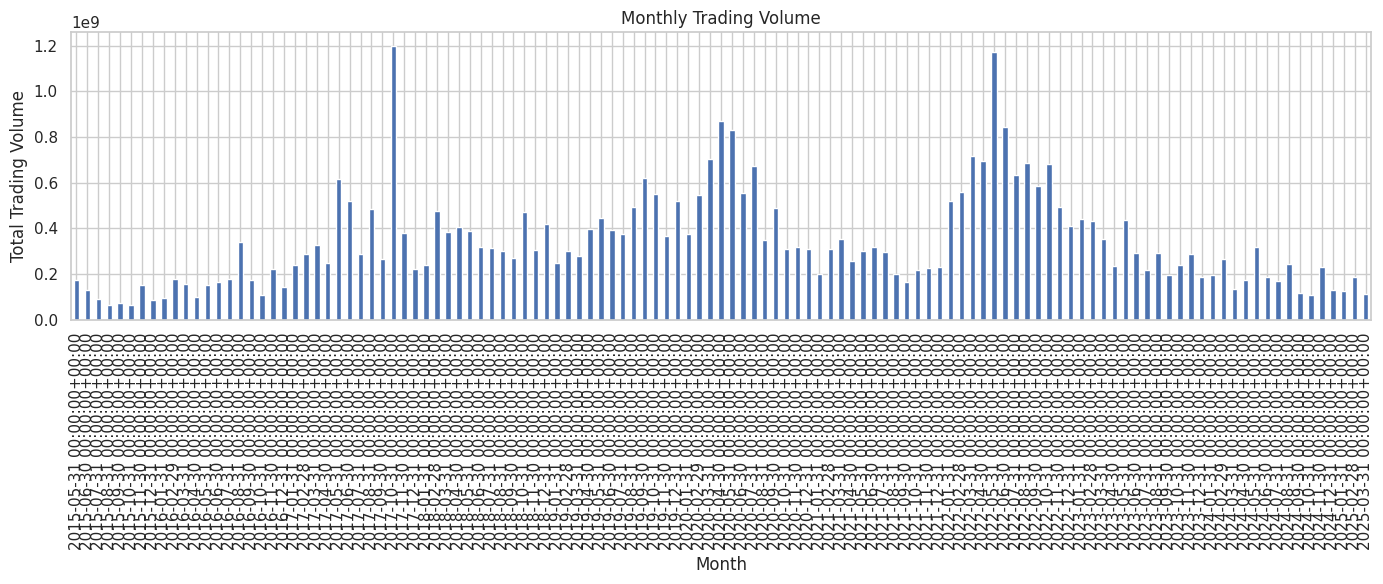

In [ ]:
plt.figure(figsize=(14, 6))

monthly_summary['volume'].plot(kind='bar')

plt.title('Monthly Trading Volume')
plt.xlabel('Month')
plt.ylabel('Total Trading Volume')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Step 21: Prepare financial summary statistics

In [ ]:
financial_summary = pd.DataFrame({
    'Metric': [
        'Average Daily Return (%)',
        'Return Variance',
        'Return Standard Deviation (%)',
        'Maximum Daily Return (%)',
        'Minimum Daily Return (%)',
        'Average Trading Volume',
        'Maximum Trading Volume',
        'Average Daily Price Change',
        'Average Daily Price Range (%)'
    ],

    'Value': [
        df['daily_return'].mean(),
        df['daily_return'].var(),
        df['daily_return'].std(),
        df['daily_return'].max(),
        df['daily_return'].min(),
        df['volume'].mean(),
        df['volume'].max(),
        df['daily_price_change'].mean(),
        df['volatility_percentage'].mean()
    ]
})

display(financial_summary)

,Metric,Value
0,Average Daily Return (%),2.148063e-01
1,Return Variance,1.378075e+01
2,Return Standard Deviation (%),3.712244e+00
3,Maximum Daily Return (%),2.383834e+01
4,Minimum Daily Return (%),-1.858534e+01
5,Average Trading Volume,1.657049e+07
6,Maximum Trading Volume,2.089590e+08
7,Average Daily Price Change,-7.732090e-03
8,Average Daily Price Range (%),4.543249e+00


Step 22: Identify high-volatility trading days

In [ ]:
volatility_threshold = df['volatility_percentage'].quantile(0.95)

high_volatility_days = df[
    df['volatility_percentage'] > volatility_threshold
]

print("95th Percentile Threshold:", volatility_threshold)

print("Number of High-Volatility Days:", len(high_volatility_days))

display(high_volatility_days[
    ['open', 'high', 'low', 'close', 'volume',
     'daily_return', 'volatility_percentage']
])

95th Percentile Threshold: 9.364716332061825
Number of High-Volatility Days: 124


,open,high,low,close,volume,daily_return,volatility_percentage
date,,,,,,,
2015-05-21 04:00:00+00:00,2.800000,2.874000,2.411000,2.568000,123039000,NaN,16.535717
2015-05-22 04:00:00+00:00,2.607000,3.110000,2.600000,2.831000,28412000,10.241433,19.562715
2015-05-27 04:00:00+00:00,3.067000,3.081000,2.700000,2.750000,7976000,-7.251262,12.422564
2015-06-15 04:00:00+00:00,3.397000,3.812000,3.292000,3.550000,16943000,5.560513,15.307623
2015-06-17 04:00:00+00:00,3.963000,4.213000,3.801000,3.863000,15952000,1.364466,10.396157
...,...,...,...,...,...,...,...
2023-01-13 05:00:00+00:00,35.799999,39.070000,35.669998,38.889999,24097400,5.794345,9.497211
2023-05-04 04:00:00+00:00,54.869999,59.820000,53.880001,57.299999,88927300,23.838337,10.825585
2023-05-05 04:00:00+00:00,57.299999,62.539001,57.020000,62.029999,43079500,8.254799,9.631765


Step 23: Export the processed dataset and reports

In [ ]:
df.to_csv('Shopify_Stock_Week4_Analysis.csv')

monthly_summary.to_csv('Shopify_Monthly_Summary.csv')

financial_summary.to_csv('Shopify_Financial_Summary.csv', index=False)

high_volatility_days.to_csv('Shopify_High_Volatility_Days.csv')

print("All Week 4 reports exported successfully.")

All Week 4 reports exported successfully.
